# DNS Exfiltration Detection: Metaheuristic Feature Selection (ACO, PSO, Enhanced RLGWO)

This notebook (1) builds train/validation/test splits of the ISP-derived DNS exfiltration dataset, (2) trains Random Forest and XGBoost baselines on all 17 features, (3) runs three feature-selection optimisers that search for 8-10 features, (4) re-trains both classifiers on each selected subset, and (5) compares results with McNemar tests, timings and figures.

**Credits:** ACO adapted from Talabani et al. (2025), Future Internet 17, 211. PSO adapted from the IJCSNS (2014) intrusion-feature-selection paper. Dataset and baseline settings follow Ia et al. (DNS Exfiltration Dataset, Mendeley Data). Enhanced RLGWO is imported from `Enhanced_detection.py`.

**Run order:** top to bottom. Stored outputs come from earlier runs, so re-run before publishing.

> Note: the subsets and metrics in this exploratory notebook differ from the final report. The report's results come from `Corrected_Validation_Only_DNS_Experiment.ipynb`.

## 1. Setup

Extra imports used by later cells (JSON saving, memory clean-up, timing, confusion matrices).

In [ ]:
import json, gc, time
from sklearn.metrics import confusion_matrix

**What this cell does:** Imports the main libraries: pandas/numpy, Random Forest, XGBoost, metrics and the dataset class.

In [ ]:
import pandas as pd, numpy as np
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score
from xgboost import XGBClassifier
from exfiltration_dataset import ExfiltrationDataset


**What this cell does:** Loads `Enhanced_detection.py` (Enhanced RLGWO optimiser, baseline RLGWO, fitness function, DQN network). The file must sit next to this notebook.

In [ ]:
import importlib.util

spec = importlib.util.spec_from_file_location(
    "enhanced_detection",
    "Enhanced_detection.py"
)
enhanced_detection = importlib.util.module_from_spec(spec)
spec.loader.exec_module(enhanced_detection)

EnhancedBinaryRLGWO = enhanced_detection.EnhancedBinaryRLGWO # feature selection optimizer-EnhancedBinaryRLGWO
BinaryRLGWO = enhanced_detection.BinaryRLGWO # feature selection optimizer-BinaryRLGWO
evaluate_features_fast = enhanced_detection.evaluate_features_fast # fitness function from enhanced
DuelingDQN = enhanced_detection.DuelingDQN #neural network class,used by the enhanced version

## 2. Optimiser implementations

**What this cell does:** Defines `BinaryACO`, ant colony feature selection adapted from Talabani et al. (2025). Documents every change made to the paper's method.

In [ ]:
import numpy as np
from tqdm import tqdm

class BinaryACO:
    """
    ACO feature selection adapted for this project (17-feature DNS
    exfiltration dataset, evaluate_features_fast fitness), following the
    core probability/pheromone equations from:

    Talabani, H.S.; Abdul, Z.K.; Mohammed Saleh, H.M. (2025). "DNS over
    HTTPS Tunneling Detection System Based on Selected Features via Ant
    Colony Optimization." Future Internet, 17, 211.
    https://doi.org/10.3390/fi17050211

    Adaptations made for this project:
    - Interface matches BinaryRLGWO / EnhancedBinaryRLGWO / BinaryPSO:
      __init__(n_dimensions, population_size, generations).run(evaluate_func)
    - Fitness function is evaluate_features_fast (weighted F1 - feature
      count penalty), not raw accuracy as in the original paper.
    - population_size/generations reduced from the paper's 30 ants /
      500 iterations to match this project's compute budget (24.5M-row
      dataset); paper's original values kept as commented defaults.
    - Reinforcement rule corrected to Delta_T_i^k = rho * f(S_k), so that
      higher-fitness subsets receive MORE pheromone, consistent with the
      paper's own stated intent ("subsets with higher accuracies are
      favored" / "features ... receive greater reinforcement"). The
      paper's literal published equation (rho / f(S_k)) would do the
      opposite and is treated here as a likely typo in the source PDF.
    """

    def __init__(self, n_dimensions, population_size, generations,
                 evaporation_rate=0.5, alpha=1.0, beta=1.0, heuristic=None):
        self.n_dimensions = n_dimensions
        self.population_size = population_size   # "number of ants" (paper default: 30)
        self.generations = generations            # "iterations" (paper default: 500)
        self.rho = evaporation_rate                # paper default: 0.5
        self.alpha = alpha                         # pheromone importance factor, paper default: 1
        self.beta = beta                           # heuristic importance factor
        # Heuristic value eta_i per feature. No feature-specific heuristic is
        # defined in the paper beyond pheromone, so default to uniform (1.0)
        # for every feature, which reduces the rule to pure pheromone-guided
        # selection when beta has no extra information source.
        self.heuristic = heuristic if heuristic is not None else np.ones(n_dimensions)

    def _construct_subset(self, pheromone):
        """
        Builds one ant's feature subset using the paper's probability rule:
            P_i(t) = [T_i(t)^alpha * eta_i^beta] / sum_{j in NotYet} [T_j(t)^alpha * eta_j^beta]
        Ants pick a random subset size each time (paper does not fix subset
        size), but always end with at least 1 feature selected.
        """
        not_yet = list(range(self.n_dimensions))
        subset = []
        size = np.random.randint(1, self.n_dimensions + 1)

        for _ in range(size):
            if not not_yet:
                break
            weights = np.array([
                (pheromone[i] ** self.alpha) * (self.heuristic[i] ** self.beta)
                for i in not_yet
            ])
            weights = np.clip(weights, 1e-12, None)  # avoid all-zero weights
            probs = weights / weights.sum()
            chosen = np.random.choice(not_yet, p=probs)
            subset.append(chosen)
            not_yet.remove(chosen)

        individual = np.zeros(self.n_dimensions, dtype=int)
        individual[subset] = 1
        return individual

    def run(self, evaluate_func):
        pheromone = np.ones(self.n_dimensions)
        best_individual_so_far, best_fitness_so_far = None, -np.inf
        history = []

        progress_bar = tqdm(range(1, self.generations + 1), desc="Binary ACO (Talabani et al. 2025, adapted)")
        for gen in progress_bar:
            population = np.array([self._construct_subset(pheromone) for _ in range(self.population_size)])
            fitnesses = np.array([evaluate_func(ind.tolist())[0] for ind in population])

            gen_best_idx = np.argmax(fitnesses)
            if fitnesses[gen_best_idx] > best_fitness_so_far:
                best_fitness_so_far = fitnesses[gen_best_idx]
                best_individual_so_far = population[gen_best_idx].copy()

            # Evaporation: T_i(t+1) = (1 - rho) * T_i(t)
            pheromone = (1 - self.rho) * pheromone

            # Reinforcement (corrected direction): Delta_T_i^k = rho * f(S_k) if F_i in S_k else 0
            for ind, fit in zip(population, fitnesses):
                fit_clamped = max(fit, 0.0)
                pheromone += (self.rho * fit_clamped) * ind

            history.append(best_fitness_so_far)
            progress_bar.set_postfix(
                best_fitness=f"{best_fitness_so_far:.4f}",
                features=f"{int(best_individual_so_far.sum())}"
            )

        return best_individual_so_far.tolist(), best_fitness_so_far, history

**What this cell does:** Defines `BinaryPSO`, binary particle swarm feature selection adapted from the IJCSNS (2014) paper.

In [ ]:
import numpy as np
from tqdm import tqdm

class BinaryPSO:
    """
    Binary PSO for feature selection, adapted for this project.

    Core equations follow:
    "Intrusion Feature Selection Algorithm Based on Particle Swarm
    Optimization." International Journal of Computer Science and
    Network Security (IJCSNS), 2014.
    http://paper.ijcsns.org/07_book/201412/20141208.pdf

    Velocity update (Eq. 3):
        v_id(n+1) = w*v_id(n) + c1*r1*(p_id - x_id(n)) + c2*r2*(p_gd - x_id(n))
    Sigmoid transfer (Eq. 5):
        s(v) = 1 / (1 + exp(-v))
    Position update (Eq. 6):
        if rand() < s(v_id(n)) then x_id(n+1) = 1 else x_id(n+1) = 0

    Adaptations for this project:
    - Interface matches BinaryRLGWO / EnhancedBinaryRLGWO / BinaryACO:
      __init__(n_dimensions, population_size, generations).run(evaluate_func)
    - Fitness function is evaluate_features_fast (weighted F1 minus a
      feature-count penalty), consistent with the other optimizers used
      in this study, rather than the paper's own fitness formula.
    - V_max included (paper mentions restraining velocity to avoid x_i
      permanently locking at 0 or 1); default set empirically to 6.0.
    """

    def __init__(self, n_dimensions, population_size, generations,
                 w=0.9, c1=0.5, c2=0.3, v_max=6.0):
        # w, c1, c2 defaults taken from a closely related PSO-IDS study
        # (Kunhare & Tiwari) reporting best accuracy with C1=0.5, C2=0.3, W=0.9
        self.n_dimensions = n_dimensions
        self.population_size = population_size
        self.generations = generations
        self.w, self.c1, self.c2 = w, c1, c2
        self.v_max = v_max

    @staticmethod
    def _sigmoid(v):
        return 1 / (1 + np.exp(-v))

    def run(self, evaluate_func):
        # Step 2: random colony, random velocities
        pos = np.random.randint(0, 2, (self.population_size, self.n_dimensions)).astype(float)
        vel = np.zeros((self.population_size, self.n_dimensions))  # paper: velocity initialized to zero

        fitnesses = np.array([evaluate_func(p.astype(int).tolist())[0] for p in pos])
        pbest_pos = pos.copy()
        pbest_fit = fitnesses.copy()
        gbest_idx = np.argmax(fitnesses)
        gbest_pos = pos[gbest_idx].copy()
        gbest_fit = fitnesses[gbest_idx]
        history = [gbest_fit]

        progress_bar = tqdm(range(1, self.generations + 1), desc="Binary PSO (IJCSNS 2014, adapted)")
        for gen in progress_bar:
            r1, r2 = np.random.rand(*pos.shape), np.random.rand(*pos.shape)

            # Step 6: velocity update (Eq. 3)
            vel = (self.w * vel
                   + self.c1 * r1 * (pbest_pos - pos)
                   + self.c2 * r2 * (gbest_pos - pos))
            vel = np.clip(vel, -self.v_max, self.v_max)

            # Position update via sigmoid (Eq. 5, 6)
            s = self._sigmoid(vel)
            pos = (np.random.rand(*pos.shape) < s).astype(float)

            for i in range(self.population_size):
                if pos[i].sum() == 0:
                    pos[i, np.random.randint(self.n_dimensions)] = 1

            # Step 3: evaluate fitness
            fitnesses = np.array([evaluate_func(p.astype(int).tolist())[0] for p in pos])

            # Step 4: update pbest
            improved = fitnesses > pbest_fit
            pbest_pos[improved] = pos[improved]
            pbest_fit[improved] = fitnesses[improved]

            # Step 5: update gbest
            if fitnesses.max() > gbest_fit:
                gbest_fit = fitnesses.max()
                gbest_pos = pos[np.argmax(fitnesses)].copy()

            history.append(gbest_fit)
            progress_bar.set_postfix(best_fitness=f"{gbest_fit:.4f}", features=f"{int(gbest_pos.sum())}")

        # Step 8: return optimal feature subset
        return gbest_pos.astype(int).tolist(), gbest_fit, history

## 3. Data loading and splitting

**What this cell does:** Sets the paths to the original and modified dataset CSVs and the saved split file.

In [ ]:
from pathlib import Path

csv_path = Path("dataset.csv")              # original dataset
csv_path_modified = Path("dataset_modified.csv")  # smaller dataset
splits_path = Path("csv_row_splits.pkl")    # train/val/test row-index split

assert csv_path.exists(), "dataset.csv not found"
assert csv_path_modified.exists(), "dataset_modified.csv not found"
csv_path = Path("dataset.csv") # original dataset
csv_path_modified = Path("dataset_modified.csv") # smaller dataset
splits_path= Path("csv_row_splits.pkl")# stores train/val/test row-index split

assert csv_path.exists(), "dataset.csv not found"
assert csv_path_modified.exists(), "dataset_modified.csv not found"

**What this cell does:** Imports the `ExfiltrationDataset` class from `exfiltration_dataset.py`.

In [ ]:
from pathlib import Path
import importlib.util

# dynamic import exfiltration_dataset.py
spec = importlib.util.spec_from_file_location(
    "exfiltration_dataset",
    str(Path("exfiltration_dataset.py").resolve())
)
exfiltration_dataset = importlib.util.module_from_spec(spec)
spec.loader.exec_module(exfiltration_dataset)

# get the class from the module (adjust name if different)
ExfiltrationDataset = exfiltration_dataset.ExfiltrationDataset

**What this cell does:** Creates the 70% train, 10% validation and 20% test split by row and saves the row indices.

In [ ]:
split, split_modified=ExfiltrationDataset.create_splits(
    csv_path, csv_path_modified,     #70 train /10 middle checkpoint /20 test split by row count
    val_size=0.1, test_size=0.2,
    val_size_modified=0.1, test_size_modified=0.2,
    train_size=None, train_size_modified=None,
    random_state=42 
)
ExfiltrationDataset.save_splits(splits_path, split, split_modified)
#
print(split.value_counts())
print(split_modified.value_counts())

train    24551906
test      7014830
val       3507415
dtype: int64
train    29611
test      8460
val       4230
dtype: int64


**What this cell does:** Reloads the saved split and builds the train, validation and test datasets, extracting the 17 features and labels.

In [ ]:
splitter, splitter_modified= ExfiltrationDataset.load_splits(splits_path)
#Reloads the saved splits, then instantiates two ExfiltrationDataset objects (train and test) that read rows from both the original and modified CSVs ('all', 'both') matching their respective split assignment
ds_train= ExfiltrationDataset(
    'all', csv_path, csv_path_modified,
    'train', splitter, splitter_modified, verbose=True
)
ds_test= ExfiltrationDataset(
    'all', csv_path, csv_path_modified,
    'test', splitter, splitter_modified, verbose=True
)

ds_val = ExfiltrationDataset(
    'all', csv_path, csv_path_modified,
    'val', splitter, splitter_modified, verbose=True
)
x_val, y_val = ds_val.get_X_y('both')
y_val = y_val.astype(int)

x_train, y_train= ds_train.get_X_y('both')  
x_test, y_test= ds_test.get_X_y('both') 

y_train= y_train.astype(int)
y_test= y_test.astype(int)

print(x_train.shape, x_test.shape)
print(pd.Series(y_train).value_counts())
print(pd.Series(y_test).value_counts())

# 24581517 ,17 train     7023290, 17 test
#  

Reading original examples:
Reading row 24550000 of 24551906, 99.99% completed
Reading features of modified examples:
Reading original examples:
Reading row  7010000 of  7014830, 99.93% completed
Reading features of modified examples:
Reading original examples:
Reading row  3500000 of  3507415, 99.79% completed
Reading features of modified examples:
(24581517, 17) (7023290, 17)
0    24429561
1      151956
dtype: int64
0    6979874
1      43416
dtype: int64


**What this cell does:** Saves the extracted train and test arrays as `.npy` files so extraction need not be repeated.

In [ ]:
import numpy as np

np.save("x_train.npy", x_train)
np.save("y_train.npy", y_train)
np.save("x_test.npy", x_test)
np.save("y_test.npy", y_test)
np.save('x_val.npy', x_val)
np.save('y_val.npy', y_val)

**What this cell does:** Reloads the cached train/test arrays from disk if they exist.

In [ ]:
import numpy as np
from pathlib import Path

if Path("x_train.npy").exists():
    x_train = np.load("x_train.npy", allow_pickle=True)
    y_train = np.load("y_train.npy", allow_pickle=True)
    x_test  = np.load("x_test.npy", allow_pickle=True)
    y_test  = np.load("y_test.npy", allow_pickle=True)
    print("Loaded cached arrays from disk.")
else:
    print("No cache found — you'll need to rerun the ExfiltrationDataset extraction cell.")

X_train_all = np.asarray(x_train)
X_test_all  = np.asarray(x_test)
y_train_all = np.asarray(y_train)
y_test_all  = np.asarray(y_test)

enhanced_detection.X_train_all = X_train_all
enhanced_detection.X_test_all  = X_test_all
enhanced_detection.y_train_all = y_train_all
enhanced_detection.y_test_all  = y_test_all

print(X_train_all.shape, X_test_all.shape)

Loaded cached arrays from disk.
(24581517, 17) (7023290, 17)


**What this cell does:** Reloads the cached validation arrays from disk if they exist.

In [ ]:
if Path('x_val.npy').exists():
    x_val = np.load('x_val.npy', allow_pickle=True)
    y_val = np.load('y_val.npy', allow_pickle=True)
    print("Loaded cached val arrays from disk.")
else:
    print("No val cache found — rerun the extraction cell above.")

Loaded cached val arrays from disk.


## 4. Baselines (all 17 features)

**What this cell does:** Trains and evaluates the Random Forest baseline on all 17 features.

In [ ]:
rf= RandomForestClassifier(
    n_estimators=5,
    max_depth=20,
    class_weight=None,
    n_jobs=1,
    random_state=42
)

rf.fit(x_train, y_train)
y_pred_rf= rf.predict(x_test)
print("Random Forest Classification Results:")
print(classification_report(y_test, y_pred_rf, digits=4))

Random Forest Classification Results:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   6979874
           1     0.9996    0.9985    0.9990     43416

    accuracy                         1.0000   7023290
   macro avg     0.9998    0.9992    0.9995   7023290
weighted avg     1.0000    1.0000    1.0000   7023290



**What this cell does:** Trains and evaluates the XGBoost baseline using the settings of Ia et al. (100 trees, subsample 0.1, early stopping).

In [ ]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    objective='binary:logistic',
    n_estimators=100,          # was 50 → Žiža et al. used 100
    subsample=0.1,             # was 0.8 → Žiža et al. used 0.1
    scale_pos_weight=1,        # unbalanced, matches Žiža et al.
    eval_metric='error',       # was not set → Žiža et al. used this
    early_stopping_rounds=10,  # was not implemented → Žiža et al. used this
    n_jobs=4,
    random_state=42,
)

xgb.fit(
    x_train, y_train,
    eval_set=[(x_val, y_val)],   # REQUIRED for early stopping to work
    verbose=False
)
y_pred_xgb = xgb.predict(x_test)

**What this cell does:** Saves the baseline classification reports to `baseline_results.json`.

In [ ]:
import json
results= {
    "RandomForest": classification_report(y_test, y_pred_rf, output_dict=True),
    "XGBoost": classification_report(y_test, y_pred_xgb, output_dict=True),
}
with open("baseline_results.json", "w") as f:
    json.dump(results, f, indent=2)

## 5. Feature selection searches

**What this cell does:** Converts the cached arrays to NumPy arrays for the optimisers.

In [ ]:
from sklearn.model_selection import train_test_split


#  Loading cached full arrays (unchanged)
X_train_all = np.asarray(x_train)
X_test_all  = np.asarray(x_test)
y_train_all = np.asarray(y_train)
y_test_all  = np.asarray(y_test)


**What this cell does:** Draws stratified search subsets (500,000 training and 150,000 test rows) so each fitness evaluation is fast.

In [ ]:
X_search_500k, _, y_search_500k, _ = train_test_split(X_train_all, y_train_all, train_size=500000, stratify=y_train_all, random_state=42)
X_test_search_500k, _, y_test_search_500k, _ = train_test_split(X_test_all, y_test_all, train_size=150000, stratify=y_test_all, random_state=42)

**What this cell does:** Passes the search subsets to the `Enhanced_detection` module, which its fitness function reads.

In [ ]:



enhanced_detection.X_train_all = X_search_500k
enhanced_detection.y_train_all = y_search_500k
enhanced_detection.X_test_all = X_test_search_500k
enhanced_detection.y_test_all = y_test_search_500k

# ... run ACO / PSO / RL-GWO here, get best_sol_xxx ...



# 5. Validate best_sol_xxx on the full data

**What this cell does:** Sets the search parameters: 17 features, population 40, 15 generations.

In [ ]:
n_features   = X_train_all.shape[1]
pop_size     = 40      
generations  = 15      # 15 rounds 

**What this cell does:** Defines the fitness function: weighted F1 minus a penalty that keeps subsets at 8-10 features (ideal 9).

In [ ]:
from sklearn.metrics import f1_score, confusion_matrix

MIN_FEATURES = 8
MAX_FEATURES = 10
IDEAL = 9

def evaluate_features_fast(individual):
    selected_indices = [i for i, selected in enumerate(individual) if selected]
    n_selected = len(selected_indices)

    if n_selected < MIN_FEATURES or n_selected > MAX_FEATURES:
        return 0.0,  # worst possible fitness, unchanged from before

    X_train_subset = X_train_all[:, selected_indices]
    X_test_subset = X_test_all[:, selected_indices]

    classifier = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
    classifier.fit(X_train_subset, y_train_all)
    y_pred = classifier.predict(X_test_subset)

    f1 = f1_score(y_test_all, y_pred, average='weighted')

    tn, fp, fn, tp = confusion_matrix(y_test_all, y_pred, labels=[0, 1]).ravel()
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0

    feature_penalty = 0.002 * abs(n_selected - IDEAL)
    fitness = f1 - fpr - feature_penalty

    return fitness,

**What this cell does:** Runs the ACO, PSO and Enhanced RLGWO searches with the same budget.

In [ ]:
# ACO
aco = BinaryACO(n_features, pop_size, generations)
best_sol_aco, best_fitness_aco, history_aco = aco.run(evaluate_features_fast)

# PSO
pso = BinaryPSO(n_features, pop_size, generations)
best_sol_pso, best_fitness_pso, history_pso = pso.run(evaluate_features_fast)

# Enhanced RLGWO
enh = EnhancedBinaryRLGWO(n_features, pop_size, generations)
best_sol_enh, best_fitness_enh, history_enh = enh.run(evaluate_features_fast)

Binary PSO (IJCSNS 2014, adapted): 100%|██████████| 15/15 [55:16<00:00, 221.11s/it, best_fitness=1.0000, features=9]


Enhanced RLGWO:   0%|          | 0/15 [00:00<?, ?it/s]

**What this cell does:** Defines `save_results`, which stores each optimiser's best subset, fitness and history as `.npy`/`.json`.

In [ ]:
import numpy as np
import json

# Suffix to distinguish this run (edit as you like)
RUN_TAG = "8to10feat"  # or e.g. "v2", "20260831"

def save_results(name, best_sol, best_fitness, history, tag=RUN_TAG):
    best_sol_arr = np.array(best_sol, dtype=int)
    selected_idx = np.where(best_sol_arr == 1)[0]

    np.save(f"{name}_best_solution_{tag}.npy", best_sol_arr)
    np.save(f"{name}_selected_features_idx_{tag}.npy", selected_idx)

    results = {
        "best_fitness": float(best_fitness),
        "history": [float(v) for v in history],
        "selected_features_idx": selected_idx.tolist(),
        "n_selected": int(selected_idx.size),
    }
    with open(f"{name}_results_{tag}.json", "w") as f:
        json.dump(results, f, indent=2)

    print(f"Saved {name} results as *_{tag} files. Selected features: {selected_idx}")

**What this cell does:** Saves the results of all three optimisers.

In [ ]:
save_results("aco", best_sol_aco, best_fitness_aco, history_aco)
save_results("pso", best_sol_pso, best_fitness_pso, history_pso)
save_results("enh", best_sol_enh, best_fitness_enh, history_enh)

## 6. Validation of selected subsets

**What this cell does:** Restores the full arrays in the optimiser module after the search.

In [ ]:
# 4. Restore the FULL cached arrays for final validation
enhanced_detection.X_train_all = X_train_all
enhanced_detection.y_train_all = y_train_all
enhanced_detection.X_test_all  = X_test_all
enhanced_detection.y_test_all  = y_test_all


**What this cell does:** Defines `validate_subset`: trains XGBoost and Random Forest on a subset, then returns confusion matrices, reports and predictions.

In [ ]:
import gc

def validate_subset(selected_idx, name):
    X_train_sub = x_train[:, selected_idx]
    X_val_sub = x_val[:, selected_idx]
    X_test_sub = x_test[:, selected_idx]

    xgb = XGBClassifier(
        objective='binary:logistic', n_estimators=100, subsample=0.1,
        scale_pos_weight=1, eval_metric='error', early_stopping_rounds=10,
        n_jobs=4, random_state=42,
    )
    xgb.fit(X_train_sub, y_train, eval_set=[(X_val_sub, y_val)], verbose=False)
    y_pred_xgb = xgb.predict(X_test_sub)
    cm_xgb = confusion_matrix(y_test, y_pred_xgb)
    report_xgb = classification_report(y_test, y_pred_xgb, digits=4, output_dict=True)
    print(f"\n{name} ({len(selected_idx)} features) XGBoost")
    print(classification_report(y_test, y_pred_xgb, digits=4))
    del xgb

    rf = RandomForestClassifier(n_estimators=5, max_depth=20, n_jobs=1, random_state=42)
    rf.fit(X_train_sub, y_train)
    y_pred_rf = rf.predict(X_test_sub)
    cm_rf = confusion_matrix(y_test, y_pred_rf)
    report_rf = classification_report(y_test, y_pred_rf, digits=4, output_dict=True)
    print(f"\n{name} ({len(selected_idx)} features) Random Forest")
    print(classification_report(y_test, y_pred_rf, digits=4))
    del rf

    del X_train_sub, X_val_sub, X_test_sub
    gc.collect()

    return {
        "xgb": {"cm": cm_xgb, "report": report_xgb, "y_pred": y_pred_xgb},
        "rf":  {"cm": cm_rf,  "report": report_rf,  "y_pred": y_pred_rf},
    }

**What this cell does:** Validates the baseline and the three optimiser subsets and stores all predictions in `preds`.

In [ ]:
preds = {}
preds['Baseline'] = validate_subset(list(range(17)), 'Baseline (all 17)')
preds['ACO'] = validate_subset([0, 1, 2, 4, 6, 7, 10, 13, 15], 'ACO')
preds['PSO'] = validate_subset([0, 1, 2, 3, 5, 7, 8, 9, 14], 'PSO')
preds['Enhanced RLGWO'] = validate_subset([0, 1, 2, 4, 5, 7, 8, 9, 16], 'Enhanced RLGWO')


Baseline (all 17) (17 features) XGBoost
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   6979874
           1     0.9973    0.9967    0.9970     43416

    accuracy                         1.0000   7023290
   macro avg     0.9987    0.9983    0.9985   7023290
weighted avg     1.0000    1.0000    1.0000   7023290


Baseline (all 17) (17 features) Random Forest
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   6979874
           1     0.9996    0.9985    0.9990     43416

    accuracy                         1.0000   7023290
   macro avg     0.9998    0.9992    0.9995   7023290
weighted avg     1.0000    1.0000    1.0000   7023290


ACO (9 features) XGBoost
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   6979874
           1     0.9954    0.9942    0.9948     43416

    accuracy                         0.9999   7023290
   macro avg  

## 7. Statistical comparison

**What this cell does:** Runs pairwise McNemar tests on paired correctness for every pair of configurations and saves `mcnemar_results.csv`.

In [ ]:
import numpy as np
from scipy.stats import chi2 as chi2_dist
from itertools import combinations
import pandas as pd
model_key_map = {"y_pred_xgb": "xgb", "y_pred_rf": "rf"}

def mcnemar_test(y_true, pred_a, pred_b):
    correct_a = (pred_a == y_true)
    correct_b = (pred_b == y_true)
    n01 = int(np.sum(correct_a & ~correct_b))
    n10 = int(np.sum(~correct_a & correct_b))
    chi2_stat = (abs(n01 - n10) - 1) ** 2 / (n01 + n10) if (n01 + n10) > 0 else 0.0
    p_value = 1 - chi2_dist.cdf(chi2_stat, df=1)
    return n01, n10, chi2_stat, p_value

configs = list(preds.keys())
results = []

configs = list(preds.keys())
results = []

for clf_key, classifier_name in [('xgb', 'XGBoost'), ('rf', 'Random Forest')]:
    for a, b in combinations(configs, 2):
        n01, n10, chi2_stat, p_value = mcnemar_test(
            y_test, preds[a][clf_key]['y_pred'], preds[b][clf_key]['y_pred']
        )
        results.append({
            "Classifier": classifier_name,
            "Config A": a,
            "Config B": b,
            "n01": n01,
            "n10": n10,
            "chi2": chi2_stat,
            "p_value": p_value,
        })

df = pd.DataFrame(results)
df.to_csv("mcnemar_results.csv", index=False)
print(df.to_string(index=False))

   Classifier Config A       Config B  n01  n10      chi2      p_value
      XGBoost Baseline            ACO  374  179 68.057866 1.110223e-16
      XGBoost Baseline            PSO  198  173  1.552561 2.127578e-01
      XGBoost Baseline Enhanced RLGWO  361  193 50.341155 1.292078e-12
      XGBoost      ACO            PSO  197  367 50.640071 1.109557e-12
      XGBoost      ACO Enhanced RLGWO  311  338  1.041602 3.074491e-01
      XGBoost      PSO Enhanced RLGWO  311  168 42.096033 8.689927e-11
Random Forest Baseline            ACO  158   31 84.000000 0.000000e+00
Random Forest Baseline            PSO   58   51  0.330275 5.654971e-01
Random Forest Baseline Enhanced RLGWO  131   48 37.564246 8.845105e-10
Random Forest      ACO            PSO   51  171 63.788288 1.332268e-15
Random Forest      ACO Enhanced RLGWO  102  146  7.455645 6.323781e-03
Random Forest      PSO Enhanced RLGWO  118   42 35.156250 3.042833e-09


## 8. Runtime measurement

**What this cell does:** Times training and batch prediction for each configuration and classifier.

In [ ]:
import time
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

def time_model(selected_idx, name, model_type="rf"):
    X_train_sub = x_train[:, selected_idx]
    X_test_sub = x_test[:, selected_idx]

    if model_type == "rf":
        clf = RandomForestClassifier(n_estimators=5, max_depth=20, n_jobs=1, random_state=42)
    else:
        clf = XGBClassifier(
            objective='binary:logistic', n_estimators=50, max_depth=6,
            learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
            n_jobs=4, random_state=42
        )

    t0 = time.perf_counter()
    clf.fit(X_train_sub, y_train)
    train_time = time.perf_counter() - t0

    t0 = time.perf_counter()
    _ = clf.predict(X_test_sub)
    inference_time = time.perf_counter() - t0

    print(f"{name} | {model_type.upper()} | {len(selected_idx)} feats | train: {train_time:.3f}s | inference: {inference_time:.3f}s")
    return train_time, inference_time

configs = {
    "Baseline": list(range(17)),
    "ACO": [0, 1, 2, 4, 6, 7, 10, 13, 15],
    "PSO": [0, 1, 2, 3, 5, 7, 8, 9, 14],
    "Enhanced RLGWO": [0, 1, 2, 4, 5, 7, 8, 9, 16],
}

results = []
for name, idx in configs.items():
    for model_type in ["rf", "xgb"]:
        tt, it = time_model(idx, name, model_type)
        results.append({"config": name, "model": model_type, "n_features": len(idx), "train_s": tt, "inference_s": it})

Baseline | RF | 17 feats | train: 464.606s | inference: 4.304s
Baseline | XGB | 17 feats | train: 106.336s | inference: 3.567s
ACO | RF | 9 feats | train: 428.130s | inference: 3.769s
ACO | XGB | 9 feats | train: 84.475s | inference: 2.867s
PSO | RF | 9 feats | train: 190.496s | inference: 2.944s
PSO | XGB | 9 feats | train: 80.449s | inference: 2.998s
Enhanced RLGWO | RF | 9 feats | train: 266.989s | inference: 3.382s
Enhanced RLGWO | XGB | 9 feats | train: 76.286s | inference: 2.722s


## 9. Figures and tables

**What this cell does:** Sets plot styles, the configuration list, colours and the `save_figure` helper.

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2

FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

CONFIGS = ["Baseline", "ACO", "PSO", "Enhanced RLGWO"]
CLASSIFIERS = {"xgb": "XGBoost", "rf": "Random Forest"}
COLORS = {"xgb": "#4472C4", "rf": "#ED7D31"}

def save_figure(fig, name):
    fig.savefig(
        FIGURE_DIR / f"{name}.pdf",
        bbox_inches="tight",
    )
    fig.savefig(
        FIGURE_DIR / f"{name}.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

**What this cell does:** Computes precision, recall, F1 and false-positive rate from the confusion matrices and saves `exact_detection_metrics.csv`.

In [ ]:
metric_rows = []

for config in CONFIGS:
    for clf_key, classifier in CLASSIFIERS.items():
        cm = np.asarray(preds[config][clf_key]["cm"])

        if cm.shape != (2, 2):
            raise ValueError(
                f"{config}/{clf_key}: expected a 2×2 confusion matrix."
            )

        tn, fp, fn, tp = cm.ravel()

        precision = tp / (tp + fp) if tp + fp else 0.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0.0
        )
        fpr = fp / (tn + fp) if tn + fp else 0.0

        metric_rows.append({
            "Configuration": config,
            "Classifier": classifier,
            "Key": clf_key,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "FPR_percent": 100 * fpr,
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp),
        })

metrics_df = pd.DataFrame(metric_rows)
metrics_df.to_csv(FIGURE_DIR / "exact_detection_metrics.csv", index=False)

display(metrics_df)

,Configuration,Classifier,Key,Precision,Recall,F1,FPR_percent,TN,FP,FN,TP
0,Baseline,XGBoost,xgb,0.997327,0.996706,0.997016,0.001662,6979758,116,143,43273
1,Baseline,Random Forest,rf,0.999608,0.998457,0.999032,0.000244,6979857,17,67,43349
2,ACO,XGBoost,xgb,0.995365,0.994173,0.994768,0.002880,6979673,201,253,43163
3,ACO,Random Forest,rf,0.998984,0.996153,0.997567,0.000630,6979830,44,167,43249
4,PSO,XGBoost,xgb,0.996981,0.996476,0.996728,0.001877,6979743,131,153,43263
5,PSO,Random Forest,rf,0.999262,0.998641,0.998952,0.000458,6979842,32,59,43357
6,Enhanced RLGWO,XGBoost,xgb,0.995642,0.994518,0.995080,0.002708,6979685,189,238,43178
7,Enhanced RLGWO,Random Forest,rf,0.998801,0.997351,0.998075,0.000745,6979822,52,115,43301


**What this cell does:** Plots attack-class F1 for each configuration and classifier.

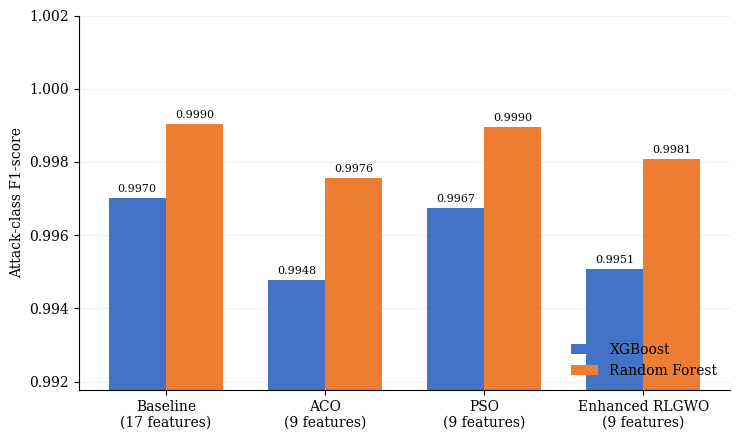

In [ ]:
x = np.arange(len(CONFIGS))
width = 0.36

fig, ax = plt.subplots(figsize=(7.5, 4.5))

for offset, clf_key in [(-width / 2, "xgb"), (width / 2, "rf")]:
    values = (
        metrics_df[metrics_df["Key"] == clf_key]
        .set_index("Configuration")
        .loc[CONFIGS, "F1"]
        .to_numpy()
    )

    bars = ax.bar(
        x + offset,
        values,
        width,
        label=CLASSIFIERS[clf_key],
        color=COLORS[clf_key],
    )

    ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels([
    "Baseline\n(17 features)",
    "ACO\n(9 features)",
    "PSO\n(9 features)",
    "Enhanced RLGWO\n(9 features)",
])
ax.set_ylabel("Attack-class F1-score")
ax.set_ylim(max(0, metrics_df["F1"].min() - 0.003), 1.002)
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()
save_figure(fig, "f1_comparison")

**What this cell does:** Plots normalised confusion matrices for all eight configuration/classifier pairs.

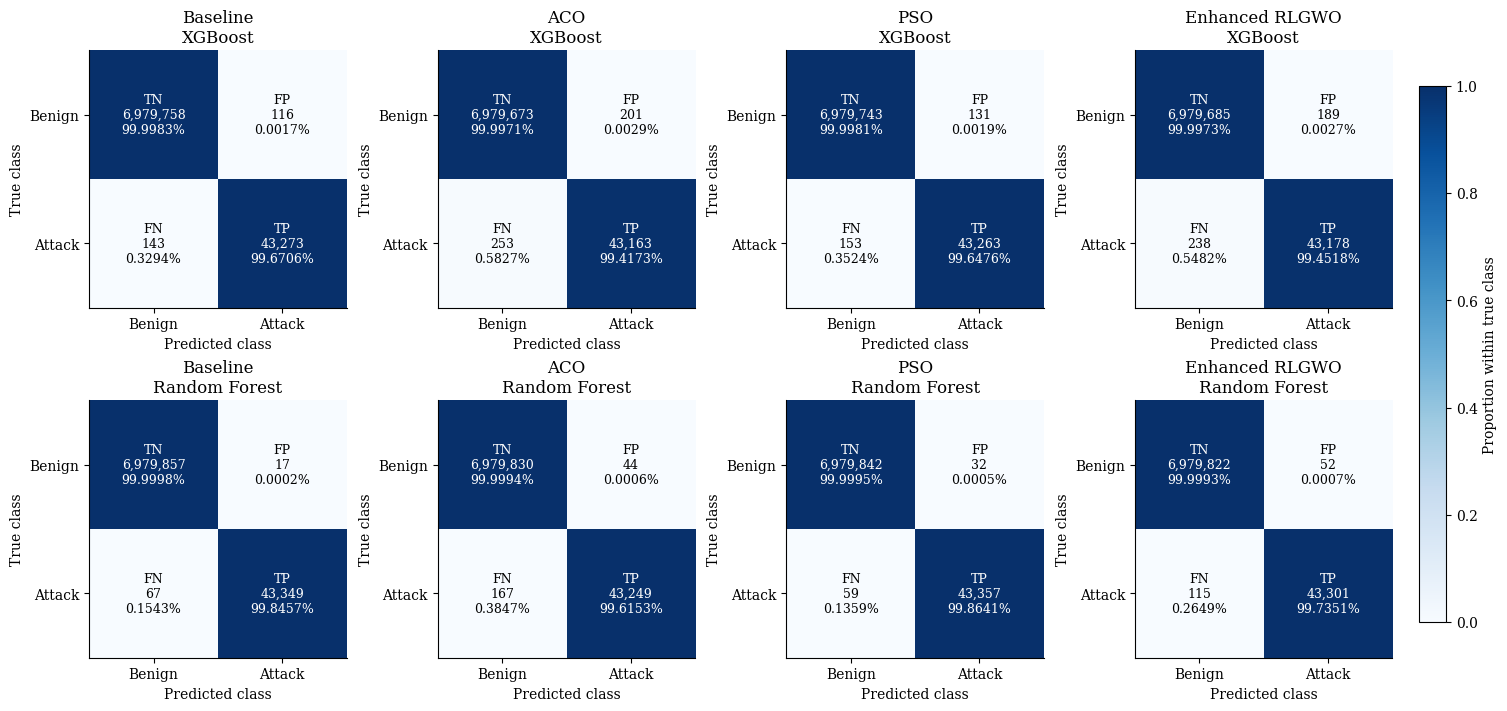

In [ ]:
fig, axes = plt.subplots(
    2, 4,
    figsize=(15, 7),
    constrained_layout=True,
)

cell_names = [["TN", "FP"], ["FN", "TP"]]

for row, (clf_key, classifier) in enumerate(CLASSIFIERS.items()):
    for col, config in enumerate(CONFIGS):
        ax = axes[row, col]
        cm = np.asarray(
            preds[config][clf_key]["cm"],
            dtype=np.int64,
        )

        row_totals = cm.sum(axis=1, keepdims=True)
        normalized = np.divide(
            cm.astype(float),
            row_totals,
            out=np.zeros_like(cm, dtype=float),
            where=row_totals != 0,
        )

        image = ax.imshow(
            normalized,
            cmap="Blues",
            vmin=0,
            vmax=1,
        )

        for i in range(2):
            for j in range(2):
                ax.text(
                    j, i,
                    (
                        f"{cell_names[i][j]}\n"
                        f"{cm[i, j]:,}\n"
                        f"{normalized[i, j] * 100:.4f}%"
                    ),
                    ha="center",
                    va="center",
                    fontsize=9,
                    color="white" if normalized[i, j] > 0.5 else "black",
                )

        ax.set_xticks([0, 1], ["Benign", "Attack"])
        ax.set_yticks([0, 1], ["Benign", "Attack"])
        ax.set_xlabel("Predicted class")
        ax.set_ylabel("True class")
        ax.set_title(f"{config}\n{classifier}")

colorbar = fig.colorbar(
    image,
    ax=axes.ravel().tolist(),
    fraction=0.02,
    pad=0.02,
)
colorbar.set_label("Proportion within true class")

save_figure(fig, "confusion_matrices_all")

**What this cell does:** Plots training and inference times. The timing values are typed in by hand, so update them from the timing step above.

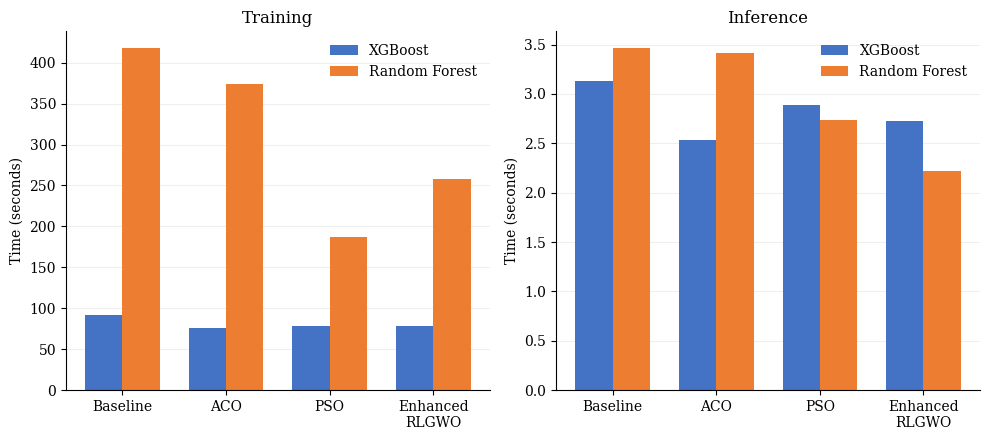

In [ ]:
timing_df = pd.DataFrame({
    "Configuration": CONFIGS,
    "RF_train": [417.515, 374.041, 186.475, 258.478],
    "XGB_train": [91.917, 75.845, 78.406, 77.771],
    "RF_inference": [3.461, 3.412, 2.737, 2.223],
    "XGB_inference": [3.132, 2.530, 2.888, 2.721],
})

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
x = np.arange(len(CONFIGS))
width = 0.36

for ax, suffix, title in [
    (axes[0], "train", "Training"),
    (axes[1], "inference", "Inference"),
]:
    ax.bar(
        x - width / 2,
        timing_df[f"XGB_{suffix}"],
        width,
        color=COLORS["xgb"],
        label="XGBoost",
    )
    ax.bar(
        x + width / 2,
        timing_df[f"RF_{suffix}"],
        width,
        color=COLORS["rf"],
        label="Random Forest",
    )

    ax.set_xticks(x, [
        "Baseline", "ACO", "PSO", "Enhanced\nRLGWO"
    ])
    ax.set_ylabel("Time (seconds)")
    ax.set_title(title)
    ax.legend(frameon=False)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.tight_layout()
save_figure(fig, "timing_comparison")

**What this cell does:** Plots which of the 17 features each optimiser selected.

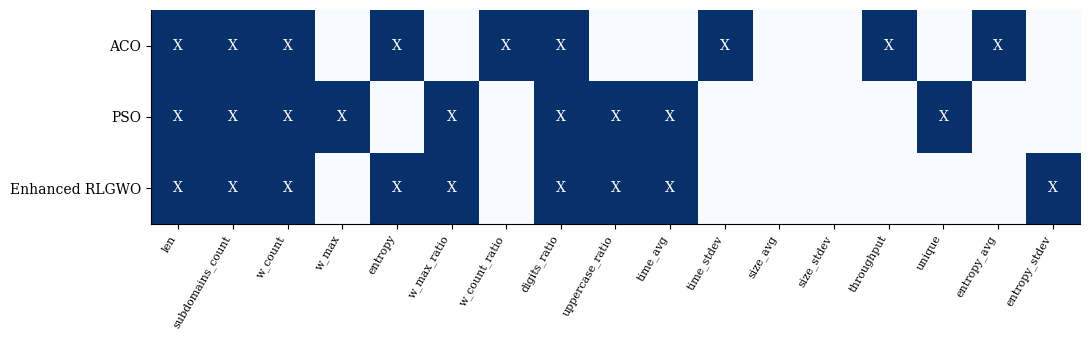

In [ ]:
feature_names = [
    "len", "subdomains_count", "w_count", "w_max", "entropy",
    "w_max_ratio", "w_count_ratio", "digits_ratio",
    "uppercase_ratio", "time_avg", "time_stdev", "size_avg",
    "size_stdev", "throughput", "unique", "entropy_avg",
    "entropy_stdev",
]

selected_features = {
    "ACO": [0, 1, 2, 4, 6, 7, 10, 13, 15],
    "PSO": [0, 1, 2, 3, 5, 7, 8, 9, 14],
    "Enhanced RLGWO": [0, 1, 2, 4, 5, 7, 8, 9, 16],
}

selection = np.zeros((3, len(feature_names)), dtype=int)

for row, indices in enumerate(selected_features.values()):
    selection[row, indices] = 1

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.imshow(selection, cmap="Blues", vmin=0, vmax=1, aspect="auto")

ax.set_yticks(range(3), list(selected_features))
ax.set_xticks(
    range(len(feature_names)),
    feature_names,
    rotation=60,
    ha="right",
    fontsize=8,
)

for row in range(3):
    for col in range(len(feature_names)):
        if selection[row, col]:
            ax.text(
                col, row, "X",
                ha="center", va="center",
                color="white",
                fontsize=10,
            )

fig.tight_layout()
save_figure(fig, "feature_selection_matrix")

**What this cell does:** Plots McNemar significance as negative log10 p-values.

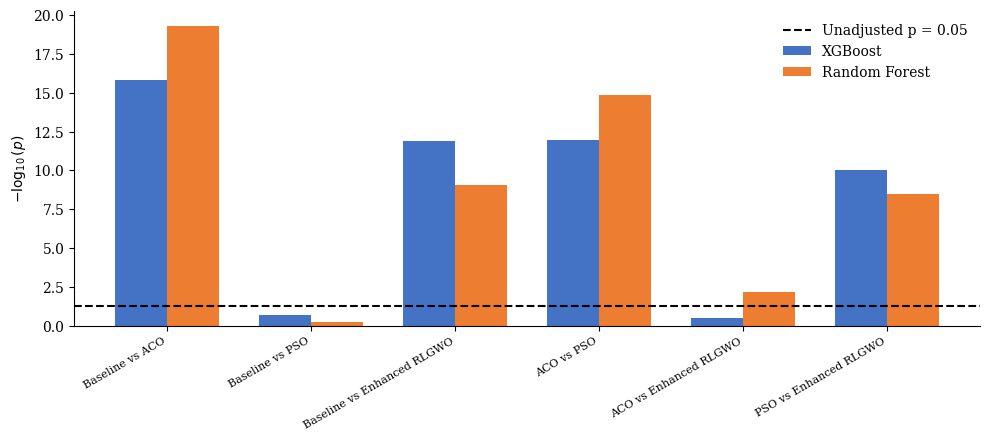

In [ ]:
mcnemar_df = df.copy()

required = {"Classifier", "Config A", "Config B", "chi2"}
if not required.issubset(mcnemar_df.columns):
    raise ValueError("Use the DataFrame from your McNemar test loop.")

mcnemar_df["p_value"] = chi2.sf(mcnemar_df["chi2"], df=1)
mcnemar_df["neg_log10_p"] = (
    -chi2.logsf(mcnemar_df["chi2"], df=1) / np.log(10)
)

mcnemar_df["Comparison"] = (
    mcnemar_df["Config A"] + " vs " + mcnemar_df["Config B"]
)

pairs = mcnemar_df["Comparison"].drop_duplicates().tolist()
x = np.arange(len(pairs))
width = 0.36

fig, ax = plt.subplots(figsize=(10, 4.5))

for offset, clf_key in [(-width / 2, "xgb"), (width / 2, "rf")]:
    values = (
        mcnemar_df[
            mcnemar_df["Classifier"] == CLASSIFIERS[clf_key]
        ]
        .set_index("Comparison")
        .loc[pairs, "neg_log10_p"]
        .to_numpy()
    )

    ax.bar(
        x + offset,
        values,
        width,
        label=CLASSIFIERS[clf_key],
        color=COLORS[clf_key],
    )

ax.axhline(
    -np.log10(0.05),
    color="black",
    linestyle="--",
    label="Unadjusted p = 0.05",
)

ax.set_xticks(x, pairs, rotation=30, ha="right", fontsize=8)
ax.set_ylabel(r"$-\log_{10}(p)$")
ax.legend(frameon=False)
fig.tight_layout()

mcnemar_df.to_csv(
    FIGURE_DIR / "mcnemar_results_recomputed.csv",
    index=False,
)
save_figure(fig, "mcnemar_significance")